# CI/CD and MLOps for the pizza shop

Our data pipeline works on a laptop. That is the easy part. Three harder questions come next:

| Question | Short name | What it means here |
|---|---|---|
| "I changed one line. Is everything still correct?" | **CI** (continuous integration) | A robot runs our checks on every change |
| "How does the new version reach the shop safely?" | **CD** (continuous delivery) | We ship the same way every time, and we can undo it |
| "Is the forecast still good next month?" | **MLOps** | We track, test, release and watch the model, like code |

```
 code change ──▶ CI: run the checks ──▶ CD: release ──▶ nightly pipeline ──▶ marts
      ▲                                                                       │
      │                                                                       ▼
      │                                         model ◀── train ◀── mart_sales_daily
      │                                           │
      │                                           ▼
      └──── retrain when the monitor says ◀── forecast ──▶ compare with what really sold
            "the model went stale"
```

### The business view in one table
Engineers ask "can we automate it?". The shop owner asks **"when, how often, what does it cost, and who decides?"**
This is our answer. Part 5 explains every row, with our own numbers.

| Job | When (Bangkok time) | How often | Why then |
|---|---|---|---|
| CI tests | on every pull request | many times a day | a bad change is cheapest to fix before it is merged |
| Code release (CD) | 02:30 to 05:30, Mon to Wed nights | 1 to 2 a week | shop closed, sources not landed yet, quiet days |
| Nightly pipeline | 06:30 (retry 07:15 and 07:45) | daily | the delivery apps' files land at about 06:00 |
| If it fails | retry a late file, never retry bad data. Page a human at 07:45 | only when needed | a retry fixes a late file, but not a wrong item name |
| Forecast + monitor | 07:00 | daily, 4 to 8 days ahead | needs yesterday's actuals. We order stock on Monday and Thursday, so we look ahead to the end of the order cycle |
| Retrain | Monday 07:30, or when the alarm fires | weekly + on alarm | Monday is our quietest day |
| Review with the owner | monthly | 12 a year | thresholds are about money, so the owner decides them |

**How to use this notebook.** Run it top to bottom. Every step has a short explanation, and the code
comments say *why*, not only *what*. Nothing here deploys anywhere real. Everything happens in a
folder called `_lab/` next to this notebook, so you can open the files and look.

The full pipeline lives in one file: [`pipeline/pizza_pipeline.py`](../pipeline/pizza_pipeline.py).
The checks live in [`pipeline/test_pizza_pipeline.py`](../pipeline/test_pizza_pipeline.py).
This notebook explains both.

| Word | Plain meaning |
|---|---|
| **test** | A small piece of code that checks one thing must be true |
| **gate** | A check that can stop the job. Red means stop |
| **release** | A frozen, labelled copy of the code (v0.1.0, v0.2.0) |
| **baseline** | A dumb rival the model must beat. Ours: "same weekday last week" |
| **registry** | A list of every trained model with its score and stage |
| **drift** | The shop changed, so the old model no longer fits |
| **WAPE** | Total forecast miss divided by total units sold. Lower is better. 0.30 means "off by 30%" |

In [1]:
# Setup. Plain pandas and numpy. Nothing to install except: pip install pandas numpy matplotlib pytest jupyter
import json, shutil, subprocess, sys, hashlib, importlib.util
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repo root, so the notebook works whether you start it from notebooks/ or from the root
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "pipeline"))
import pizza_pipeline as pp          # <- the whole pipeline. We import it, so there is ONE copy of the logic

# everything we create goes into _lab/ (git ignores it). Delete the folder any time to start fresh.
WORK = Path("_lab")
if WORK.exists():
    shutil.rmtree(WORK)
WORK.mkdir()

D = lambda i: pp.HISTORY_START + timedelta(days=i)     # "day number i" -> a real date. Day 0 is 1 Aug 2026

def tree(root: Path, max_files=6):
    # print a folder as a tree, so we can SEE what each step wrote
    for p in sorted(root.rglob("*")):
        if p.is_dir():
            kids = [k for k in p.iterdir() if k.is_file()]
            print("    " * (len(p.relative_to(root).parts) - 1) + p.name + "/" + (f"   ({len(kids)} files)" if kids else ""))

print("pipeline module:", pp.__file__.split("madt-pizza-shop")[-1])

pipeline module: /pipeline/pizza_pipeline.py

## Part 1 · The thing we protect: one night of the pipeline

Before we protect something, let us look at it. `pizza_pipeline.py` has four zones, each a folder:

`landing` (files exactly as sent) → `raw` (one row per record, nothing fixed) → `trusted` (clean, deduped, one timezone) → `refined` (the marts)

First we make one day of fake source files. They are messy on purpose, like the real POS, Grab and LINE MAN:
different time formats, different item names, repeated orders.

In [2]:
day = D(0)
lake = pp.new_lake(WORK / "demo_lake")        # an empty lake: four empty zone folders
src = WORK / "demo_sources"

# the sources produce files. `truth` is what we secretly planted, so we can check the pipeline later
truth = pp.generate_day(day, src, rain=False)

# look at ONE record from each source. Same kind of fact, three different shapes. That is the mess.
pos  = json.loads(next((src / "pos").glob("*.json")).read_text())
grab = json.loads(next((src / "grab").glob("*.json")).read_text())
lm   = json.loads(next((src / "lineman").glob("*.json")).read_text())["orders"]
print("POS      ", json.dumps(pos[0])[:230], "...")
print("GRAB     ", json.dumps(grab[0])[:230], "...")
print("LINE MAN ", json.dumps(lm[0])[:230], "...")
print()
print("Notice: POS time has +07:00, Grab time ends in Z (that is UTC), LINE MAN uses dd/mm/yyyy.")
print(f"POS has {len(pos)} records for {len({r['pos_order_id'] for r in pos})} orders, because every order is exported twice.")

POS       {"pos_order_id": "P-20260801-QR000", "ordered_at": "2026-08-01T21:53:32+07:00", "channel": "QR_DINEIN", "status": "PLACED", "lines": [{"sku": "COKE", "qty": 2, "unit_price": 35}, {"sku": "MAR-M", "qty": 1, "unit_price": 219}]} ...
GRAB      {"orderID": "GF-20260801-000", "orderTime": "2026-08-01T18:45:37Z", "orderStatus": "COMPLETED", "commissionPct": 30, "items": [{"itemName": "Large Pepperoni Pizza", "quantity": 1, "itemPrice": 359}, {"itemName": "Medium Pepperoni  ...
LINE MAN  {"order_no": "LM-20260801-000", "created_at": "01/08/2026 14:00", "menu": [{"name": "Pepperoni Pizza (L)", "qty": 1, "subtotal": 359}]} ...

Notice: POS time has +07:00, Grab time ends in Z (that is UTC), LINE MAN uses dd/mm/yyyy.
POS has 138 records for 69 orders, because every order is exported twice.

In [3]:
# run the nightly job: land -> ingest to raw -> process to trusted -> build marts
stats = pp.run_nightly(lake, src, day)
print(stats)
print()
tree(lake)

{'business_date': '2026-08-01', 'lines_in': 357, 'duplicates_removed': 126, 'lines_out': 231, 'orders': 135}

landing/
    grab/
        2026-08-02/   (1 files)
    lineman/
        2026-08-02/   (1 files)
    pos/
        2026-08-02/   (1 files)
raw/
    grab/
        ingest_date=2026-08-02/   (1 files)
    lineman/
        ingest_date=2026-08-02/   (1 files)
    pos/
        ingest_date=2026-08-02/   (1 files)
refined/   (1 files)
trusted/
    fct_order_line/
        business_date=2026-08-01/   (1 files)

In [4]:
# the finished mart: units sold per business day x channel x item. This table feeds the dashboard AND the forecast
mart_day = pp.read_mart(lake)
print("Rows:", len(mart_day), " Units in the mart:", int(mart_day.units_sold.sum()), " Units we planted:", sum(truth.values()))
mart_day.head(8)

Rows: 20  Units in the mart: 273  Units we planted: 273

,business_date,channel_code,menu_item_nk,units_sold,net_sales_thb,orders
0,2026-08-01,QR_DINEIN,PEP-L,29,9541.0,22
1,2026-08-01,QR_DINEIN,PEP-M,17,4403.0,14
2,2026-08-01,QR_DINEIN,MAR-M,24,5256.0,20
3,2026-08-01,QR_DINEIN,HAW-L,12,3708.0,12
4,2026-08-01,QR_DINEIN,COKE,27,945.0,23
5,2026-08-01,PHONE,PEP-L,5,1645.0,4
6,2026-08-01,PHONE,PEP-M,5,1295.0,5
7,2026-08-01,PHONE,MAR-M,5,1095.0,5


The mart holds exactly the units we planted, even though POS sent every order twice, Grab repeated some orders,
and some orders came after midnight. **This sentence is the thing CI will protect.** If someone changes the code and
the two numbers stop matching, we want a red light before the change reaches the shop.

## Part 2 · CI: a robot colleague that checks every change

**The idea.** Every change goes through a *pull request*. CI runs the checks automatically. If anything is red, the change
cannot be merged. Nobody has to remember to run the tests.

We have **two layers of protection**. They catch different problems:

| Layer | Runs when | Catches | Example |
|---|---|---|---|
| **Quality gates** (inside the pipeline) | every night, on real data | bad **data** | Grab renames an item and nobody told us |
| **Tests** (this part) | on every code change, on fake data | bad **code** | someone breaks the business-day rule |

### 2.1 Quality gates (already inside the pipeline)
Each gate is a name, a pass/fail, and a detail. The same list is used by the nightly job and by the tests.

In [5]:
# run the gates by hand on the day we just processed
for name, ok, detail in pp.quality_gates(pp.read_trusted(lake)):
    print("PASS" if ok else "FAIL", "|", name, detail)

PASS | every item is mapped to a menu key unmapped: 0
PASS | every line has a channel 
PASS | quantity and price are positive 
PASS | no duplicate lines left 

### 2.2 What a test looks like
A test is a small function with a name that says what must be true. It has three steps:
**arrange** (set up data), **act** (run our code), **assert** (check the answer). One false `assert` and the test fails.

Here are two real tests from `pipeline/test_pizza_pipeline.py`:

In [6]:
text = (ROOT / "pipeline" / "test_pizza_pipeline.py").read_text()
start = text.index("def test_order_after_midnight")
end = text.index("# ---------- 2.")
print(text[start:end].strip())

def test_order_after_midnight_belongs_to_the_day_before():
    ts = pd.Series([pd.Timestamp("2026-09-12 00:40", tz=pp.BKK), pd.Timestamp("2026-09-12 10:00", tz=pp.BKK)])
    assert list(pp.business_date(ts)) == [date(2026, 9, 11), date(2026, 9, 12)]


def test_every_item_in_every_app_has_a_menu_key():
    for sku in pp.SKUS:
        assert ("GRAB", pp.GRAB_NAME[sku]) in pp.NAME_MAP
        assert ("LINEMAN", pp.LM_NAME[sku]) in pp.NAME_MAP

### 2.3 Run the whole test file (this is what the CI robot does)
We call `pytest` from the notebook. On GitHub the robot runs the same command on a fresh machine.

In [7]:
r = subprocess.run([sys.executable, "-m", "pytest", str(ROOT / "pipeline"), "-v", "-p", "no:cacheprovider", "--no-header"],
                   capture_output=True, text=True, cwd=ROOT)
# keep the output short: one line per test, then the summary
for line in r.stdout.splitlines():
    if "PASSED" in line or "FAILED" in line or "passed" in line or "failed" in line:
        print(line.replace(str(ROOT) + "/", ""))

pipeline/test_pizza_pipeline.py::test_order_after_midnight_belongs_to_the_day_before PASSED [  4%]
pipeline/test_pizza_pipeline.py::test_every_item_in_every_app_has_a_menu_key PASSED [  9%]
pipeline/test_pizza_pipeline.py::test_mart_recovers_the_units_we_planted PASSED [ 14%]
pipeline/test_pizza_pipeline.py::test_messy_sources_really_were_messy_and_got_cleaned PASSED [ 19%]
pipeline/test_pizza_pipeline.py::test_rerunning_a_day_gives_the_same_answer PASSED [ 23%]
pipeline/test_pizza_pipeline.py::test_no_negative_or_missing_numbers_in_the_mart PASSED [ 28%]
pipeline/test_pizza_pipeline.py::test_unknown_item_name_stops_the_job PASSED [ 33%]
pipeline/test_pizza_pipeline.py::test_model_beats_the_baseline_on_calm_days PASSED [ 38%]
pipeline/test_pizza_pipeline.py::test_forecasts_are_never_negative PASSED [ 42%]
pipeline/test_pizza_pipeline.py::test_promotion_rule[cand0-None-0.4-True] PASSED [ 47%]
pipeline/test_pizza_pipeline.py::test_promotion_rule[cand1-None-0.4-False] PASSED [ 52%]
pipeli

### 2.4 Let us break something on purpose
A teammate "simplifies" the business-day rule and forgets the 10 hour shift. The code still runs. No error. Only the
numbers are wrong, and nobody would notice by eye. Watch what CI says.

In [8]:
good_rule = pp.business_date

def buggy_rule(ts):
    return ts.dt.date                      # the bug: a calendar day, not a business day (forgot the 10:00 start)

pp.business_date = buggy_rule              # swap the rule, like a bad code change would
try:
    results = pp.ci_checks(WORK / "ci_run")
finally:
    pp.business_date = good_rule           # always put it back

for name, ok, detail in results:
    print("PASS" if ok else "FAIL", "|", name, "|", detail)

FAIL | mart units equal the units we planted, every day | 21 days differ
PASS | re-running a day gives the same result | 
PASS | no negative or missing numbers in the mart | 

Red. The robot caught it in seconds, on fake data, before any real order was touched. On GitHub this shows as a red cross
on the pull request, and the **Merge** button is blocked.

### 2.5 The CI recipe (a GitHub Actions file)
This is *only shown here as text*. It is not saved under `.github/workflows/`, so nothing runs by accident.
If the team later turns it on, this is the file.

```yaml
name: ci
on:
  pull_request:            # run on every pull request ...
    branches: [main]       # ... that wants to merge into main

jobs:
  test:
    runs-on: ubuntu-latest           # a fresh, empty machine every time: no "works on my laptop"
    steps:
      - uses: actions/checkout@v4                 # 1. get the code
      - uses: actions/setup-python@v5             # 2. install Python
        with: { python-version: "3.11" }
      - run: pip install pandas numpy pytest      # 3. install what the code needs
      - run: pytest pipeline -q                   # 4. run the tests. Any failure = red = cannot merge
```

**What CI cannot catch.** A brand new app that sends a format we have never seen. No test can know about it.
That is why the nightly quality gates exist too. Tests guard the code. Gates guard the data.

## Part 3 · CD: ship the same way every time, and be able to undo it

CI answers "is this change safe?". CD answers "how does it get to the shop?".

The rule of CD is boring on purpose:

1. Make a **release**: a frozen folder with a version number and a label card. Never edit it again.
2. **Smoke test** the release on a tiny fake day. If it fails, the release is blocked.
3. **Deploy** = move one pointer (`CURRENT`) to the new release. Nothing is copied by hand.
4. **Rollback** = move the pointer back. Old releases are still there.

We build a tiny version of this with folders, so you can see every moving part.

In [9]:
REL, PROD = WORK / "releases", WORK / "prod"
REL.mkdir(); PROD.mkdir()

def make_release(version, note, patch=None):
    """Freeze the code into releases/<version>/. `patch` simulates a code change that was merged."""
    folder = REL / version
    folder.mkdir()                                              # fails if the version already exists: releases never change
    code_text = (ROOT / "pipeline" / "pizza_pipeline.py").read_text()
    if patch:
        assert patch[0] in code_text, "patch target not found"
        code_text = code_text.replace(*patch)
    (folder / "pizza_pipeline.py").write_text(code_text)
    card = {"version": version, "note": note,
            "fingerprint": hashlib.sha256(code_text.encode()).hexdigest()[:12]}   # a short hash: change one letter, it changes
    (folder / "RELEASE.json").write_text(json.dumps(card, indent=1))
    return card

def smoke_test(version):
    """Run the RELEASE's own code on one tiny fake day. True only if the mart equals the planted truth."""
    spec = importlib.util.spec_from_file_location(f"rel_{version.replace('.', '_')}", REL / version / "pizza_pipeline.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    scratch = WORK / "smoke"
    lake_ = mod.new_lake(scratch / "lake")
    shutil.rmtree(scratch / "src", ignore_errors=True)
    planted = mod.generate_day(mod.HISTORY_START, scratch / "src", rain=False)
    mod.run_nightly(lake_, scratch / "src", mod.HISTORY_START)
    return int(mod.read_mart(lake_).units_sold.sum()) == sum(planted.values())

def deploy(version):
    if not smoke_test(version):
        print(f"BLOCKED  {version}: the smoke test failed, so CURRENT was not moved.")
        return False
    (PROD / "CURRENT").write_text(version)                      # the whole deploy is this one line
    print(f"DEPLOYED {version}")
    return True

def current():
    return (PROD / "CURRENT").read_text() if (PROD / "CURRENT").exists() else "(nothing yet)"

In [10]:
# release 1: the code as it is today
print(make_release("v0.1.0", "first release"))
deploy("v0.1.0")
print("prod is running:", current())

{'version': 'v0.1.0', 'note': 'first release', 'fingerprint': 'a52a1d2a5de8'}
DEPLOYED v0.1.0
prod is running: v0.1.0

In [11]:
# release 2: a small, good change (the model must now beat production by 5%, not 2%, before it is promoted)
print(make_release("v0.2.0", "stricter promotion rule", patch=("min_gain: float = 0.02", "min_gain: float = 0.05")))
deploy("v0.2.0")
print("prod is running:", current())

{'version': 'v0.2.0', 'note': 'stricter promotion rule', 'fingerprint': 'ca3883d6fbe1'}
DEPLOYED v0.2.0
prod is running: v0.2.0

In [12]:
# release 3: a BAD change slips in (the same business-day bug as before). The smoke test must stop it
print(make_release("v0.3.0", "tidy up business_date", patch=("return (ts - pd.Timedelta(hours=10)).dt.date", "return ts.dt.date")))
deploy("v0.3.0")
print("prod is still running:", current())

{'version': 'v0.3.0', 'note': 'tidy up business_date', 'fingerprint': 'ecd87427037d'}
BLOCKED  v0.3.0: the smoke test failed, so CURRENT was not moved.
prod is still running: v0.2.0

In [13]:
# rollback: suppose v0.2.0 had a problem we only noticed later. Rolling back is the same one-line move
deploy("v0.1.0")
print("prod is running:", current())
print()
print("Releases on disk (old ones are never deleted):")
for card in sorted(REL.glob("*/RELEASE.json")):
    c = json.loads(card.read_text()); print(" ", c["version"], c["fingerprint"], "-", c["note"])

DEPLOYED v0.1.0
prod is running: v0.1.0

Releases on disk (old ones are never deleted):
  v0.1.0 a52a1d2a5de8 - first release
  v0.2.0 ca3883d6fbe1 - stricter promotion rule
  v0.3.0 ecd87427037d - tidy up business_date

### The CD recipe (GitHub Actions, shown as text only)
Two triggers. One ships code when it lands on `main`. One runs the pipeline every night.

```yaml
name: cd
on:
  push:
    branches: [main]            # ship when something is merged into main
  schedule:
    - cron: "30 23 * * *"       # and also every morning at 06:30 Bangkok time (23:30 UTC the day before). See Part 5 for why 06:30

jobs:
  ship:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.11" }
      - run: pip install pandas numpy pytest
      - run: pytest pipeline -q                  # never ship if the tests are red
      - run: python make_release.py              # (imaginary script) our "make a release + smoke test" step from above
      - run: python run_nightly.py               # (imaginary script) run last night's data through the pipeline
```

The two scripts marked *imaginary* do not exist in the repo yet. They show the shape of the real thing.

In a real shop, "deploy" would copy the release to a server, a container image, or a cloud job.
The idea is the same as our `CURRENT` pointer: **new version in, old version kept, one step to go back.**

## Part 4 · MLOps: a forecast we can trust next month

**The question.** How many units of each item will we sell tomorrow, per channel? The kitchen uses this to prep dough and order cheese.

**What "ops" adds to a model.** Training a model once is a homework exercise. MLOps is everything after:

`track every experiment → register the model → release only if it passes a rule → forecast every night → compare with reality → retrain when it goes stale`

Our data comes from the pipeline itself: `mart_sales_daily`. First we let the pipeline run night after night for 90 days.

In [14]:
# 90 nights of the pipeline, one after another. This takes about 10 seconds.
# why: the model must learn from the SAME table the dashboard uses, so one clean source of truth feeds everything
lake = pp.new_lake(WORK / "lake")
history = pp.build_history(lake, WORK / "sources", days=90)

mart = pp.read_mart(lake)                       # business date x channel x item, zeros included
cal = pp.calendar(pp.HISTORY_START, 90)         # facts we know BEFORE a day happens: weekday, payday, rain forecast
data = pp.with_calendar(mart, cal)              # one table: sales + what we knew that day
print(len(data), "rows =", data.business_date.nunique(), "days x", data.channel_code.nunique(), "channels x", data.menu_item_nk.nunique(), "items")
data.head(5)

1800 rows = 90 days x 4 channels x 5 items

,business_date,channel_code,menu_item_nk,units_sold,net_sales_thb,orders,weekday,payday,rain
0,2026-08-01,QR_DINEIN,PEP-L,23,7567.0,18,5,True,True
1,2026-08-01,QR_DINEIN,PEP-M,14,3626.0,13,5,True,True
2,2026-08-01,QR_DINEIN,MAR-M,19,4161.0,16,5,True,True
3,2026-08-01,QR_DINEIN,HAW-L,6,1854.0,6,5,True,True
4,2026-08-01,QR_DINEIN,COKE,29,1015.0,26,5,True,True


### 4.1 "Today" is day 65
We pretend to stand at day 65 (5 October). We can only look at days up to 65. The pipeline will keep running after that,
and we will come back to see what happened.

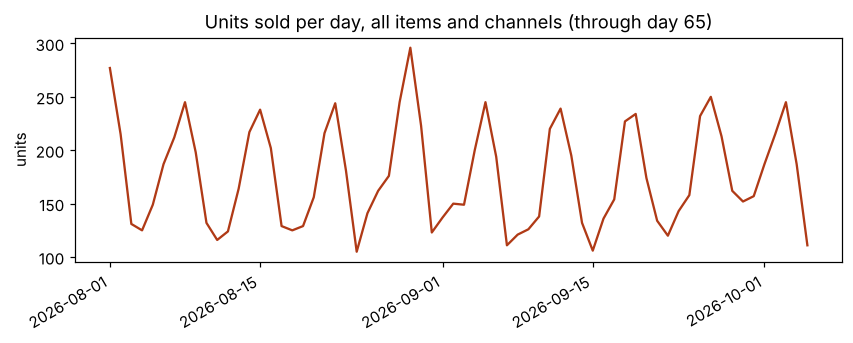

In [15]:
today = 65
seen = data[data.business_date <= D(today)]

daily = seen.groupby("business_date").units_sold.sum()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(daily.index, daily.values, color="#b03a16")
ax.set_title("Units sold per day, all items and channels (through day 65)")
ax.set_ylabel("units")
fig.autofmt_xdate()
plt.show()
# what to see: a weekly wave (Friday and Saturday are the busiest). That is a pattern a model can learn.

### 4.2 The dumb rival: the baseline
Before any model, we need a rival that needs no learning: **"same weekday, last week"**.
If a fancy model cannot beat this, the fancy model is not worth running. We also split time into two parts:

- **train** (days 0 to 55): the model may learn from these
- **validation** (days 56 to 65): the model has never seen these, so the score is honest

We split by *date*, not at random, because tomorrow is always after today.

In [16]:
train = pp.split_by_date(data, D(0), D(55))
valid = pp.split_by_date(data, D(56), D(65))

baseline_pred = pp.baseline_predict(data, valid)          # looks at the same weekday 7 days earlier
baseline_wape = pp.wape(valid.units_sold, baseline_pred)
print(f"baseline WAPE on validation: {baseline_wape:.3f}   (off by about {baseline_wape:.0%})")

baseline WAPE on validation: 0.393   (off by about 39%)

### 4.3 Train, and track every experiment
Our model is a small linear model on `log(1 + units)`. Its inputs: which item and channel it is, the weekday, whether it is
payday, and whether it rains (rain helps delivery, hurts walk-ins). Every weight is a number we can read.

We try three values of one setting (`alpha`, how careful the model is). We **write down every run**. A real tool like
MLflow does this for you. Here a plain list does the same job. The habit matters more than the tool:
*if a result is not written down, it did not happen.*

In [17]:
experiments = []                                   # our tiny "experiment tracker": one dict per run

for alpha in [0.1, 1.0, 10.0]:
    model = pp.RidgeForecaster(alpha=alpha).fit(train)           # learn from the training days only
    score = pp.wape(valid.units_sold, model.predict(valid))      # grade on days it has never seen
    experiments.append({"run": len(experiments) + 1, "alpha": alpha, "half_life_days": None,
                        "train_days": "0-55", "valid_days": "56-65", "val_wape": round(score, 4)})

pd.DataFrame(experiments)

,run,alpha,half_life_days,train_days,valid_days,val_wape
0,1,0.1,None,0-55,56-65,0.2717
1,2,1.0,None,0-55,56-65,0.2745
2,3,10.0,None,0-55,56-65,0.3218


In [18]:
# pick the best run by the validation score, and keep the model object for registering
best = min(experiments, key=lambda e: e["val_wape"])
model_v1 = pp.RidgeForecaster(alpha=best["alpha"]).fit(train)
print("best run:", best)
print(f"baseline {baseline_wape:.3f}  vs  model {best['val_wape']:.3f}")

best run: {'run': 1, 'alpha': 0.1, 'half_life_days': None, 'train_days': '0-55', 'valid_days': '56-65', 'val_wape': 0.2717}
baseline 0.393  vs  model 0.272

### 4.4 Register the model and apply the release rule
A model that scored well on your laptop is not "in production". It becomes a **version in the registry**, with its score,
the days it learned from, and a stage (`candidate` → `production` → `archived`).

Then a written rule decides if it may go live. Writing the rule as code means the same rule applies every time, to every
person, at 3 a.m. The rule (`promotion_decision`):
- the score must be a real number
- it must **beat the baseline**
- it must beat the current production model by at least 2%, if there is one

In [19]:
reg = pp.ModelRegistry(WORK / "registry.json")        # a JSON file here. In real life: MLflow Model Registry

v1 = reg.register(model_v1, {"wape": best["val_wape"]}, trained_on=(D(0), D(55)), note="first model")

ok, why = pp.promotion_decision({"wape": best["val_wape"]}, reg.production() and reg.production()["metrics"], baseline_wape)
print("promote v1?", ok, "-", why)
if ok:
    reg.promote(v1)

reg.table()

promote v1? True - first model that beats the baseline

,version,stage,trained_on,wape,note
0,1,production,2026-08-01 to 2026-09-25,0.2717,first model


### 4.5 Forecast every night and *save the forecasts*
From now on, each night the production model forecasts the next day. Time moves forward: days 66 to 89 happen.
(How far ahead we really need to look is a business question. Part 5.5 answers it.)
We save each forecast in a table, `fct_forecast`, with the **model version** that made it.
Why save them? Because later we want to ask "how wrong were we?", and you can only grade a forecast you kept.

In [20]:
production = reg.load()                                  # always load "whatever is production", never a hard-coded file
live = pp.split_by_date(data, D(66), D(89))              # the 24 days after "today"
pp.write_forecast(lake, live, production.predict(live), model_version=reg.production()["version"])

fc = pd.read_csv(lake / "refined" / "fct_forecast.csv")
print(len(fc), "forecast rows saved. Grain = business date x channel x item x model version")
fc.head(5)

480 forecast rows saved. Grain = business date x channel x item x model version

,business_date,channel_code,menu_item_nk,forecast_units,model_version
0,2026-10-06,QR_DINEIN,PEP-L,9.72,1
1,2026-10-06,QR_DINEIN,PEP-M,5.07,1
2,2026-10-06,QR_DINEIN,MAR-M,6.15,1
3,2026-10-06,QR_DINEIN,HAW-L,4.35,1
4,2026-10-06,QR_DINEIN,COKE,10.50,1


### 4.6 Monitor: compare the forecast with what really sold
The pipeline keeps filling `mart_sales_daily`, so every forecast gets its answer one day later.
Monitoring is just a join between `fct_forecast` and the mart, plus an alarm rule:

> **Alarm if the last 14 days are more than 25% worse than the validation score.**

validation WAPE was 0.272. Last 14 days: 0.384.  Alarm: True

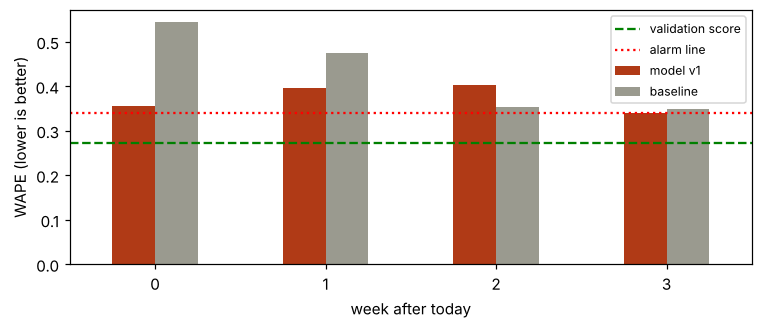

,model v1,baseline
week,,
0,0.355,0.544
1,0.395,0.474
2,0.404,0.353
3,0.340,0.350


In [21]:
fva = pp.forecast_vs_actual(lake)                         # forecasts joined with actual units

def monitor(fva, reference_wape, last_days=14, tolerance=1.25):
    recent = fva[fva.business_date > max(fva.business_date) - timedelta(days=last_days)]
    now = pp.wape(recent.units_sold, recent.forecast_units)
    return now, now > reference_wape * tolerance

now, alarm = monitor(fva, best["val_wape"])
print(f"validation WAPE was {best['val_wape']:.3f}. Last 14 days: {now:.3f}.  Alarm: {alarm}")

# compare with the dumb baseline on the same days, week by week
base = live.assign(base=pp.baseline_predict(data, live))
base["week"] = base.business_date.map(lambda x: (x - D(66)).days // 7)
fva["week"] = fva.business_date.map(lambda x: (x - D(66)).days // 7)
weekly = pd.DataFrame({
    "model v1": fva.groupby("week").apply(lambda x: pp.wape(x.units_sold, x.forecast_units), include_groups=False),
    "baseline": base.groupby("week").apply(lambda x: pp.wape(x.units_sold, x.base), include_groups=False)})

fig, ax = plt.subplots(figsize=(8, 3))
weekly.plot.bar(ax=ax, color=["#b03a16", "#9a9a8f"], rot=0)
ax.axhline(best["val_wape"], color="green", ls="--", label="validation score")
ax.axhline(best["val_wape"] * 1.25, color="red", ls=":", label="alarm line")
ax.set_xlabel("week after today"); ax.set_ylabel("WAPE (lower is better)"); ax.legend(fontsize=8)
plt.show()
weekly.round(3)
# what to see: the model sits above the alarm line, and by weeks 2 and 3 the dumb baseline is just as good or better

### 4.7 Diagnose: where is it wrong?
An alarm says *something* is wrong. The next question is *where*. **Bias** = (forecast − actual) ÷ actual.
Near zero is fine. A big positive number means "we forecast much more than we sold".

In [22]:
pp.bias_report(fva, by="channel_code")

,channel_code,actual,forecast,bias,verdict
0,GRAB,728.0,688.74,-0.054,ok
1,LINEMAN,539.0,500.43,-0.072,ok
2,PHONE,287.0,260.89,-0.091,ok
3,QR_DINEIN,534.0,882.12,0.652,DRIFT


Walk-in (`QR_DINEIN`) is far off: we forecast about two thirds more than we sold. The other channels are fine.
The owner then tells us: **a competitor opened next door on 6 October.** The model could never know this, because nothing in
its inputs says "competitor". This is called **drift**: the shop changed, and the old model describes the old shop.
No code was wrong, so CI stays green. Only *monitoring* can see this. That is why MLOps needs it.

### 4.8 Retrain, and compare fairly
We retrain on everything we know now (days 0 to 79) and keep days 80 to 89 aside to grade.
One new setting: a **half-life**. Newer days get more weight, so the model follows the shop as it is now, not as it was in August.
We try a few values and, as before, write every run down.

In [23]:
train2 = pp.split_by_date(data, D(0), D(79))
valid2 = pp.split_by_date(data, D(80), D(89))

for half_life in [None, 21, 14, 10]:
    m = pp.RidgeForecaster(alpha=1.0, half_life_days=half_life).fit(train2)
    experiments.append({"run": len(experiments) + 1, "alpha": 1.0, "half_life_days": half_life,
                        "train_days": "0-79", "valid_days": "80-89", "val_wape": round(pp.wape(valid2.units_sold, m.predict(valid2)), 4)})

pd.DataFrame(experiments).fillna("none")      # "none" = no extra weight on newer days

,run,alpha,half_life_days,train_days,valid_days,val_wape
0,1,0.1,none,0-55,56-65,0.2717
1,2,1.0,none,0-55,56-65,0.2745
2,3,10.0,none,0-55,56-65,0.3218
3,4,1.0,none,0-79,80-89,0.3537
4,5,1.0,21.0,0-79,80-89,0.3312
5,6,1.0,14.0,0-79,80-89,0.3305
6,7,1.0,10.0,0-79,80-89,0.3312


In [24]:
# FAIR comparison: grade production (v1), the baseline and the new candidate on the SAME days (80-89)
runs2 = [e for e in experiments if e["train_days"] == "0-79"]
best2 = min(runs2, key=lambda e: e["val_wape"])
model_v2 = pp.RidgeForecaster(alpha=best2["alpha"], half_life_days=best2["half_life_days"]).fit(train2)

v1_now = pp.wape(valid2.units_sold, reg.load().predict(valid2))
base_now = pp.wape(valid2.units_sold, pp.baseline_predict(data, valid2))
print(f"on days 80-89:  production v1 {v1_now:.3f}   baseline {base_now:.3f}   candidate {best2['val_wape']:.3f}")

v2 = reg.register(model_v2, {"wape": best2["val_wape"]}, trained_on=(D(0), D(79)), note=f"retrained, half-life {best2['half_life_days']} days")
ok, why = pp.promotion_decision({"wape": best2["val_wape"]}, {"wape": v1_now}, base_now)     # production is re-scored on the same days
print("promote v2?", ok, "-", why)
if ok:
    reg.promote(v2)
reg.table()

on days 80-89:  production v1 0.386   baseline 0.352   candidate 0.331
promote v2? True - beats production by at least 2% (0.331 vs 0.386)

,version,stage,trained_on,wape,note
0,1,archived,2026-08-01 to 2026-09-25,0.2717,first model
1,2,production,2026-08-01 to 2026-10-19,0.3305,"retrained, half-life 14 days"


The rule promoted v2 without a human. The old model is now `archived`, **not deleted**, so we can still go back.
Notice one more thing: we compared production *on the new days*, not on its old score of 0.274. An old score on old days says nothing about today.

### 4.9 Rollback
Suppose v2 starts behaving strangely next week. Going back is one call:

In [25]:
print("rollback ->", "v%d" % reg.rollback(), "is production again")
print(reg.table()[["version", "stage", "wape", "note"]].to_string(index=False))
print()
reg.promote(v2)                                           # put v2 back, we want it
print("v2 promoted again. Production is now v%d" % reg.production()["version"])

rollback -> v1 is production again
 version      stage   wape                         note
       1 production 0.2717                  first model
       2   archived 0.3305 retrained, half-life 14 days

v2 promoted again. Production is now v2

### 4.10 The same ideas with real tools
Our small versions show the *idea*. Real teams use tools that do the same jobs with more features.

| What we built | Real tool | Why you would switch |
|---|---|---|
| `experiments` list | **MLflow Tracking** | a web page to compare hundreds of runs |
| `ModelRegistry` (JSON file) | **MLflow Model Registry** | stages, approvals, who promoted what |
| `promotion_decision` | a CI/CD job that reads the metrics | the rule runs without anyone clicking |
| `monitor`, `bias_report` | **Evidently**, **WhyLabs**, or a dashboard on `fct_forecast` | many drift tests, alerts to Slack |
| nightly run | **Airflow**, **GitHub Actions cron**, **Cloud Scheduler** | retries, logs, dependencies between jobs |
| the CSV lake | **Parquet + DuckDB / a warehouse** | speed and size (see `data_flow_demo.ipynb`) |

## Part 5 · The business view: when, how often, what it costs, who decides

Parts 2 to 4 showed *how*. A shop owner asks four other questions. We answer each one with our own data.

1. **When** should each job run? (the shop's clock)
2. **How often**, for CI/CD and for the model?
3. **What does it cost** when the forecast is wrong, and what does a better model save?
4. **Who decides** the rules?

### 5.1 The shop's clock
Every time below comes from something real: when we open and close, when customers come, and when the
delivery apps hand over yesterday's files.

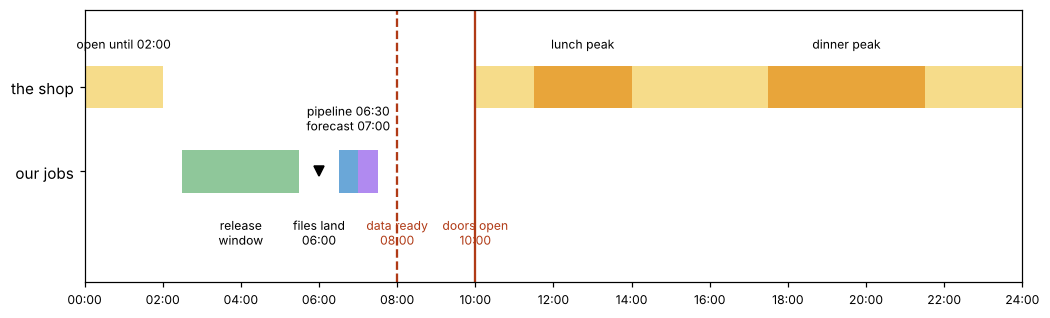

In [26]:
# draw one day, 00:00 to 24:00. Top row = the shop. Bottom row = our data jobs.
fig, ax = plt.subplots(figsize=(11, 3.2))

for a, b in [(0, 2), (10, 24)]:                                   # open hours: 10:00 to 02:00 next morning
    ax.barh(1, b - a, left=a, height=.5, color="#f6dc8a")
for a, b in [(11.5, 14), (17.5, 21.5)]:                           # lunch and dinner peaks (from our generator)
    ax.barh(1, b - a, left=a, height=.5, color="#e8a53a")

ax.barh(0, 3, left=2.5, height=.5, color="#8fc79a")               # release window: after close, before files land
ax.barh(0, .5, left=6.5, height=.5, color="#6aa7d8")              # nightly pipeline
ax.barh(0, .5, left=7.0, height=.5, color="#b08af0")              # forecast + monitor
ax.plot([6], [0], marker="v", color="black")                      # the delivery apps' files land
ax.axvline(8, color="#b03a16", ls="--"); ax.axvline(10, color="#b03a16", ls="-")

ax.text(1, 1.45, "open until 02:00", ha="center", fontsize=8)
ax.text(12.75, 1.45, "lunch peak", ha="center", fontsize=8); ax.text(19.5, 1.45, "dinner peak", ha="center", fontsize=8)
ax.text(4, -.55, "release\nwindow", ha="center", fontsize=8, va="top")
ax.text(6, -.55, "files land\n06:00", ha="center", fontsize=8, va="top")
ax.text(6.75, .45, "pipeline 06:30\nforecast 07:00", ha="center", fontsize=8, va="bottom")
ax.text(8, -.55, "data ready\n08:00", ha="center", fontsize=8, va="top", color="#b03a16")
ax.text(10, -.55, "doors open\n10:00", ha="center", fontsize=8, va="top", color="#b03a16")
ax.set_yticks([0, 1]); ax.set_yticklabels(["our jobs", "the shop"])
ax.set_xticks(range(0, 25, 2)); ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)], fontsize=8)
ax.set_xlim(0, 24); ax.set_ylim(-1.3, 1.9)
plt.show()

| Time | What happens | Why exactly then |
|---|---|---|
| 02:00 | Shop closes. The business day ends | last order of the day is in |
| 02:30 to 05:30 | **Release window** | no customers, and 3 hours to fix a problem before the data jobs start |
| 06:00 | Grab and LINE MAN hand over yesterday's files | their schedule, not ours (T+1) |
| 06:30 | **Nightly pipeline** | it must wait for the last file |
| 07:00 | **Forecast and monitor** | the forecast needs yesterday's actuals |
| 08:00 | **Data ready** (our promise) | the kitchen decides dough and toppings before opening |
| 10:00 | Doors open | after this time, a broken job is felt by customers |

### A mismatch worth knowing about
Our design docs say the warehouse load runs at **03:00**. But the delivery files land at about **06:00**.
A 03:00 run would be missing every Grab and LINE MAN order. Let us see exactly what the owner would be looking at:

In [27]:
# run ONE business day twice. First "at 03:00": only the POS file has arrived. Then "at 06:30": everything has arrived.
day = D(3)
lake_t = pp.new_lake(WORK / "timing_lake")
src_t = WORK / "timing_sources"
planted = pp.generate_day(day, src_t, rain=False)

# pretend only the POS folder exists at 03:00
src_pos = WORK / "timing_pos_only"
shutil.copytree(src_t / "pos", src_pos / "pos")

pp.land(lake_t, src_pos, day); pp.ingest_raw(lake_t, day + timedelta(days=1))
pp.process_day(lake_t, day); early = pp.build_marts(lake_t)
print("03:00 run:", int(early.units_sold.sum()), "units in the mart. By channel:", early.groupby("channel_code").units_sold.sum().to_dict())

# 06:30: now everything is here. Run the SAME job again. Re-running a day replaces it (that is what the test checks)
pp.land(lake_t, src_t, day); pp.ingest_raw(lake_t, day + timedelta(days=1))
pp.process_day(lake_t, day); final = pp.build_marts(lake_t)
print("06:30 run:", int(final.units_sold.sum()), "units in the mart. Planted truth:", sum(planted.values()))
print(f"The 03:00 run was missing {1 - early.units_sold.sum() / final.units_sold.sum():.0%} of the day's units.")

03:00 run: 61 units in the mart. By channel: {'GRAB': 0, 'LINEMAN': 0, 'PHONE': 14, 'QR_DINEIN': 47}
06:30 run: 124 units in the mart. Planted truth: 124
The 03:00 run was missing 51% of the day's units.

**What we choose.** Run the full job at **06:30**. Optionally also run a quick *provisional* one at 03:00 for POS only,
which is safe **because re-running a day replaces it** (we test that). Delivery apps also settle commission up to 7 days
later (T+7), so once a week we re-run the last 7 days. This is the business reason the pipeline must be *idempotent*:
the same job can run again without making a mess.

### 5.2 CI/CD: how often, and on which days
Releasing changes the pipeline, and a mistake hurts most on our busiest days. We can choose the release days **from our own data**:

Quietest days: ['Mon', 'Tue', 'Wed'] | busiest: Sat

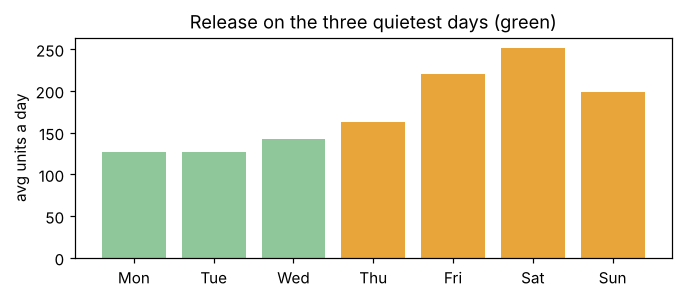

In [28]:
# average units per weekday, from the days before the competitor arrived (0 to 65)
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
per_day = seen.groupby(["business_date", "weekday"]).units_sold.sum().groupby("weekday").mean()
quiet = per_day.nsmallest(3).index

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(names, per_day.values, color=["#8fc79a" if w in quiet else "#e8a53a" for w in per_day.index])
ax.set_ylabel("avg units a day"); ax.set_title("Release on the three quietest days (green)")
plt.show()
print("Quietest days:", [names[w] for w in sorted(quiet)], "| busiest:", names[int(per_day.idxmax())])

| What runs | How often | When | Run it **more** often and... | Run it **less** often and... |
|---|---|---|---|---|
| **CI tests** | on every pull request and push | any time, about 3 minutes | nothing bad. They are cheap | bugs reach the nightly run, and the owner sees wrong numbers |
| **Code release (CD)** | 1 to 2 a week, merged code only | 02:30 to 05:30 on Mon to Wed | more changes on busy days, more risk | fixes wait. People start hiding changes in big, risky releases |
| **Nightly pipeline** | daily | 06:30, retry 07:15 and 07:45, deadline 08:00 | no gain. The sources only change once a day | the owner decides on old numbers |
| **Quality gates** | every run | inside the nightly job | (always on) | bad data is published |
| **Freshness check** ("did all 3 files land?") | daily | 07:00 | | a late Grab file silently gives a low sales number |
| **Re-run the last 7 days** | weekly | Monday 07:30 | | commission settled late is never corrected |

Two rules that do not need a meeting: **no releases on Thu to Sun nights**, and **rollback is allowed at any time, by anyone on call**.
Going back is a one-line move (Part 3), so nobody needs permission.

### 5.3 When the pipeline fails: do we retry? do we notify?
A job that works on a good night is the easy case. The owner's real question is: *"What happens at 06:30 when it breaks?"*
Two rules answer most of it:

1. **Retry only what can fix itself.** A late file may arrive in 20 minutes. A wrong item name will be wrong again in 20 minutes.
2. **Tell a human only when a retry will not help, or when the retries ran out.** A phone that rings for every small thing gets ignored.

| What went wrong | Example | Retry? | Who is told, and how | Why |
|---|---|---|---|---|
| A file is late | Grab has not delivered at 06:30 | **Yes**: 07:15, then 07:45 | nobody if it works on a retry. A quiet chat message ("worked on try 2") | most late files fix themselves |
| Still late at 07:45 | Grab never came | no more tries | **page the data engineer** | the 08:00 deadline is close, and a person can call Grab |
| The data is wrong | an app renamed an item, a negative quantity | **No** | **page the data engineer now** | the same input gives the same failure. Waiting wastes the morning |
| Our own code is broken | last week's release has a bug | no | **page now**, then roll back (Part 3) | retrying a bug hides it |
| A busy disk or network blip | a locked file | **Yes**, like a late file | only if it keeps failing | usually passes in minutes |
| It ran, but the number looks odd | sales are 40% below the same weekday last week | not applicable | quiet chat warning, **no page** | it may be real: a rainy day, a closed street |

**What does the kitchen see while we fix it?** The dashboard keeps showing yesterday's numbers, clearly marked *"as of Tuesday"*.
The data gates stop *before* anything is published, so a failed night never replaces a good table with a broken one.
If it is still broken at 08:00, the owner gets one plain message: *"Today's numbers are late. Prep from last week's same weekday."*
That fallback is exactly our **baseline** from Part 4. It is why we keep the dumb rival around.

Let us run three bad mornings and read the alerts.

In [29]:
# THREE BAD MORNINGS for the same business day. "sleep" is replaced by a fake clock so we do not really wait 45 minutes.
day = D(3)
src_full, src_partial = WORK / "fail_full", WORK / "fail_partial"
pp.generate_day(day, src_full, rain=False)
for name in ("pos", "lineman"):                                    # Grab's file is NOT here yet
    shutil.copytree(src_full / name, src_partial / name, dirs_exist_ok=True)

def show(title, out, waited):
    print(f"--- {title}")
    print(f"result: {out['status']} after {out['attempts']} try(s). Waited {waited} minutes in total.")
    print(pd.DataFrame(out["alerts"]).to_string(index=False), "\n")

# 1. Grab is late, then delivers while we wait for the retry
waited = []
def grab_delivers(seconds):
    waited.append(seconds // 60)
    shutil.copytree(src_full / "grab", src_partial / "grab", dirs_exist_ok=True)       # the file arrives during the wait
lake_a = pp.new_lake(WORK / "fail_lake_a")
show("1. Grab is late, then arrives", pp.run_with_retry(lambda: pp.run_nightly(lake_a, src_partial, day), sleep=grab_delivers), sum(waited))

# 2. Grab never delivers
shutil.rmtree(src_partial / "grab")
waited = []
lake_b = pp.new_lake(WORK / "fail_lake_b")
show("2. Grab never delivers", pp.run_with_retry(lambda: pp.run_nightly(lake_b, src_partial, day), sleep=lambda s: waited.append(s // 60)), sum(waited))
print("Anything published for this day? ->", (lake_b / "trusted" / "fct_order_line").exists(), "(no: a half-empty day is worse than a late one)\n")

# 3. Grab sends a renamed item (bad data)
src_bad = WORK / "fail_bad"
pp.generate_day(day, src_bad, rain=False)
f = next((src_bad / "grab").glob("*.json")); f.write_text(f.read_text().replace("Large Pepperoni Pizza", "Pepperoni XXL (new!)"))
waited = []
lake_c = pp.new_lake(WORK / "fail_lake_c")
show("3. Bad data: an item was renamed", pp.run_with_retry(lambda: pp.run_nightly(lake_c, src_bad, day), sleep=lambda s: waited.append(s // 60)), sum(waited))

--- 1. Grab is late, then arrives
result: ok after 2 try(s). Waited 45 minutes in total.
level                                                            message
  log nightly pipeline: try 1 failed (2026-08-04: no file yet from grab)
 chat                   nightly pipeline worked on try 2. Nothing to do. 

--- 2. Grab never delivers
result: failed after 3 try(s). Waited 75 minutes in total.
level                                                                         message
  log              nightly pipeline: try 1 failed (2026-08-04: no file yet from grab)
  log              nightly pipeline: try 2 failed (2026-08-04: no file yet from grab)
  log              nightly pipeline: try 3 failed (2026-08-04: no file yet from grab)
 page nightly pipeline still failing after 3 tries: 2026-08-04: no file yet from grab 

Anything published for this day? -> False (no: a half-empty day is worse than a late one)

--- 3. Bad data: an item was renamed
result: failed after 1 try(s). Waited 0 minu

Read the three results side by side. Case 1 costs nobody anything. Case 2 pages a human **once**, at 07:45, with the reason in the message.
Case 3 pages **immediately** and does not wait at all, because waiting cannot help.

**Who gets which message** (the owner picks the people and the channel, not the code):
| Level | Goes to | Looks like | Example |
|---|---|---|---|
| `log` | only written down | nothing | "try 1 failed (no file yet from grab)" |
| `chat` | the team chat, no sound | a message | "nightly pipeline worked on try 2" |
| `page` | the person on call, on their phone | a call or a loud message | "STOPPED, bad data, not retried: unmapped item" |

In this notebook `notify()` only collects the messages. In production that one line would call LINE, Slack or email.
The same rules apply to the model side (5.4): a failed retrain **keeps the current production model** and sends a chat message.
Nobody is paged for it, because tonight's forecast still works.

### 5.4 MLOps: how often
| What runs | How often | When | Why this rhythm |
|---|---|---|---|
| **Forecast** | daily | 07:00, the next 4 to 8 days (see 5.5) | we order stock on Monday and Thursday. The forecast must reach the end of each order cycle |
| **Monitor** (forecast vs actual) | daily | 07:00, after the nightly run | yesterday's actuals are now in the mart |
| **Scheduled retrain** | weekly | Monday 07:30 | the quietest day, and a week brings enough new data to matter |
| **Triggered retrain** | when the alarm fires | as soon as possible | the shop changed, so waiting costs money (see 5.6) |
| **Promotion** | right after a retrain | automatic if the rule says yes | the rule is written down (Part 4) |
| **Human review** | monthly | with the owner | thresholds are about money, so the owner should agree to them |

Retraining *too often* is also bad: the model starts chasing random noise and its forecasts jump around.
We therefore require a candidate to beat production by at least 2%.

### 5.5 How far ahead must we forecast? Our order cycle decides
A forecast for *tomorrow* is not what a shop needs for **ordering**. We do not order stock every day.
Suppose we order twice a week, and the supplier brings it the next morning. Then each order must last until the **next** order arrives:

> **Assumptions, not facts.** Fresh items (dough, cheese, toppings): order **Monday and Thursday**, delivered next morning.
> Drinks and boxes: order **Monday only**, delivered after 2 days. The owner should replace these with the real supplier terms.

In [30]:
ORDER_RULES = {"Fresh items (dough, cheese, toppings)": {"order_weekdays": (0, 3), "lead_days": 1},
               "Drinks and boxes": {"order_weekdays": (0,), "lead_days": 2}}

rows, week = [], pp.HISTORY_START + timedelta(days=65)          # day 65 is a Monday, 5 October
for supplier, rule in ORDER_RULES.items():
    for order_day in [d for d in (week + timedelta(days=k) for k in range(7)) if d.weekday() in rule["order_weekdays"]]:
        c = pp.order_cycle(order_day, **rule)
        rows.append({"stock": supplier, "order on": order_day.strftime("%a"), "arrives": c["first_day"].strftime("%a"),
                     "must last until": c["last_day"].strftime("%a"), "days covered": c["days_covered"],
                     "forecast must look ahead (days)": c["horizon_days"]})
cycles = pd.DataFrame(rows)
print("The nightly forecast must look", cycles["forecast must look ahead (days)"].max(), "days ahead (the longest cycle).")
cycles

The nightly forecast must look 8 days ahead (the longest cycle).

,stock,order on,arrives,must last until,days covered,forecast must look ahead (days)
0,"Fresh items (dough, cheese, toppings)",Mon,Tue,Thu,3,3
1,"Fresh items (dough, cheese, toppings)",Thu,Fri,Mon,4,4
2,Drinks and boxes,Mon,Wed,Tue,7,8


So, **yes, 3 to 4 days** for our fresh items: the Monday order covers three days and the Thursday order covers four.
Drinks and boxes are ordered once a week with a longer wait, so they need a longer look: **8 days**.
We still run the forecast **every night**, for two reasons: monitoring needs daily numbers (Part 4), and a late order (a Wednesday emergency) needs a fresh forecast.
But we **use** it on order days only. The order sheet on Monday and Thursday at 07:30 is what the buyer actually reads.

Two things change when we look further ahead:
1. **Rain.** Our model uses rain as an input. For tomorrow we know it. For day +4 we only have the weather *forecast*. We should save which weather forecast we used, and grade it too.
2. **Errors add up in a useful way.** One pizza type in one channel on one day is hard to guess. The total of a whole order cycle is easier, because the misses cancel. Let us measure it.

In [31]:
# We need many PAST cycles to measure error. Replay days 41-65 with a model that only knew days 0-40 (calm days, before the competitor).
m40 = pp.RidgeForecaster(alpha=best["alpha"]).fit(pp.split_by_date(data, D(0), D(40)))
replay = pp.split_by_date(data, D(41), D(65)).assign(forecast=lambda d: m40.predict(d))

# cut those days into the same Monday/Thursday order cycles: each day belongs to the order cycle that feeds it
rule = ORDER_RULES["Fresh items (dough, cheese, toppings)"]
def cycle_of(day):                                       # the order day whose delivery covers this day
    d = day - timedelta(days=1)
    while True:
        c = pp.order_cycle(d, **rule)
        if c["first_day"] <= day <= c["last_day"]:
            return c["order_day"]
        d -= timedelta(days=1)
replay["order_day"] = replay.business_date.map(cycle_of)

# keep only cycles that fit entirely inside the replay window
full = replay.groupby("order_day").business_date.nunique().rename("n").reset_index()
full["need"] = full.order_day.map(lambda d: pp.order_cycle(d, **rule)["days_covered"])
replay = replay[replay.order_day.isin(full[full.n == full.need].order_day)]

per_item = replay.groupby(["order_day", "menu_item_nk"])[["units_sold", "forecast"]].sum().reset_index()
daily_wape = pp.wape(replay.units_sold, replay.forecast)
cycle_wape = pp.wape(per_item.units_sold, per_item.forecast)
print(f"{per_item.order_day.nunique()} full order cycles replayed.")
print(f"error per day, channel and item (WAPE): {daily_wape:.3f}")
print(f"error per order cycle and item  (WAPE): {cycle_wape:.3f}   <- what the buyer feels")

7 full order cycles replayed.
error per day, channel and item (WAPE): 0.304
error per order cycle and item  (WAPE): 0.162   <- what the buyer feels

The order cycle is easier to forecast than a single day. That is good news for ordering, but **a smaller error is not zero**.
If we order exactly the forecast, we run out half the time. How much **extra** should we order?
It depends on which mistake costs more:

| If we order too much | If we order too little |
|---|---|
| the extra dough and toppings are thrown away | we sell out and lose the profit on every missed pizza |
| costs the **ingredients** (assumed 30% of the price) | costs the **margin** (assumed 70% of the price) |

Running out costs more than wasting, so we should lean towards ordering a bit extra. The rule is a classic from the textbooks (the *newsvendor* rule):
order enough to cover demand on **cost of running out ÷ (cost of running out + cost of waste)** of past cycles. Here that is 0.70 ÷ (0.70 + 0.30) = **70%**.

In [32]:
FOOD_COST = 0.30                                            # ASSUMPTION. Ask the owner for the real number
critical = (1 - FOOD_COST) / ((1 - FOOD_COST) + FOOD_COST)  # = 0.70: cover demand in 70% of past cycles

per_item["ratio"] = per_item.units_sold / per_item.forecast          # >1 means we under-forecast that cycle
extra = per_item.groupby("menu_item_nk").ratio.quantile(critical)    # per item, from past cycles
print(f"Cover {critical:.0%} of past cycles. Extra to order on top of the forecast, per item:")
print(((extra - 1) * 100).round(1).astype(str).add("%").to_string(), "\n")

# THE ORDER SHEET for the next Thursday order (days 69 to 72): forecast + extra
thu = pp.order_cycle(D(65) + timedelta(days=3), **rule)
nxt = pp.split_by_date(data, thu["first_day"], thu["last_day"])
sheet = (nxt.assign(forecast=m40.predict(nxt)).groupby("menu_item_nk").forecast.sum().rename("forecast"))
sheet = pd.DataFrame({"forecast units": sheet.round(), "order units": (sheet * extra.reindex(sheet.index).fillna(1)).round()})
print(f"Order sheet, Thursday {(D(65) + timedelta(days=3)).isoformat()} order, covers {thu['first_day']} to {thu['last_day']}:")
sheet

Cover 70% of past cycles. Extra to order on top of the forecast, per item:
menu_item_nk
COKE     22.8%
HAW-L    46.7%
MAR-M     4.8%
PEP-L     7.8%
PEP-M    30.0% 

Order sheet, Thursday 2026-10-08 order, covers 2026-10-09 to 2026-10-12:

,forecast units,order units
menu_item_nk,,
COKE,206.0,253.0
HAW-L,89.0,130.0
MAR-M,130.0,136.0
PEP-L,190.0,205.0
PEP-M,102.0,133.0


This is the sheet the buyer reads on Thursday at 07:30. Three limits to keep in mind:
- The **percentage comes from only a few cycles**. With real data we would use months, and we would re-check it every month with the owner.
- The cost numbers (30% / 70%) are assumptions.
- When the model goes stale (Part 4.6), these extra percentages stop being true. This is one more reason the **monitor** must watch the *cycle* error, not only the daily one.

### 5.6 What does a wrong forecast cost?
This is the question that turns "WAPE 0.33" into baht. Two kinds of miss, two different costs:

| Miss | What happens in the kitchen | Cost |
|---|---|---|
| **Too high** (we forecast more than we sold) | dough and toppings thrown away | the **ingredient cost** of the extra units |
| **Too low** (we forecast less than we sold) | we sell out, customers leave | the **profit** we did not earn |

> **Assumptions, not measurements.** We assume ingredients are 30% of the sale price, so profit lost is 70%.
> The owner should replace these two numbers with real ones. The *method* is what matters.

In [33]:
FOOD_COST = 0.30                       # ASSUMPTION (same number as in 5.5): ingredients = 30% of the price. Ask the owner for the real number

# average price per unit for each item, from our own mart
price = mart.groupby("menu_item_nk").net_sales_thb.sum() / mart.groupby("menu_item_nk").units_sold.sum()

def error_cost(df, pred):
    # baht lost over these days because the forecast was not perfect
    p = df.menu_item_nk.map(price).to_numpy()
    actual = df.units_sold.to_numpy(float)
    too_high = np.clip(pred - actual, 0, None)       # prepared but not sold  -> ingredients wasted
    too_low = np.clip(actual - pred, 0, None)        # sold out               -> profit not earned
    return float((too_high * p * FOOD_COST + too_low * p * (1 - FOOD_COST)).sum())

# the same 10 days (80 to 89) for every rival, so the comparison is fair
days_n = valid2.business_date.nunique()
rivals = {"baseline (same weekday last week)": pp.baseline_predict(data, valid2),
          "model v1 (the stale one)": reg.load(1).predict(valid2),
          "model v2 (retrained)": model_v2.predict(valid2)}

rows = []
for name, pred in rivals.items():
    c = error_cost(valid2, pred)
    rows.append({"forecast": name, "WAPE": round(pp.wape(valid2.units_sold, pred), 3),
                 "baht lost per day": round(c / days_n), "baht lost per month": round(c / days_n * 30)})
cost = pd.DataFrame(rows)
cost["saved vs v1 per month"] = cost["baht lost per month"].iloc[1] - cost["baht lost per month"]
cost

,forecast,WAPE,baht lost per day,baht lost per month,saved vs v1 per month
0,baseline (same weekday last week),0.352,6567,197023,-21218
1,model v1 (the stale one),0.386,5860,175805,0
2,model v2 (retrained),0.330,5795,173837,1968


Read the last column: that is what a good MLOps habit is worth, in baht per month, in a shop of this size. The same table also
says how much **a day of waiting** costs. If v1 loses about X baht more per day than v2, every day we run a stale model costs X baht.
That gives a business way to choose the alarm rule:

In [34]:
# How fast does the alarm fire, for two window sizes? Use v1's forecasts from day 56 (validation) to day 89.
chk = pp.split_by_date(data, D(56), D(89))
chk = chk.assign(forecast_units=model_v1.predict(chk))
reference = best["val_wape"]

def alarm_days(df, window, tolerance=1.25):
    days = sorted(df.business_date.unique())
    out = []
    for i in range(window - 1, len(days)):
        w = df[df.business_date.between(days[i - window + 1], days[i])]
        if pp.wape(w.units_sold, w.forecast_units) > reference * tolerance:
            out.append(days[i])
    return out

extra_per_day = (error_cost(valid2, rivals["model v1 (the stale one)"]) - error_cost(valid2, rivals["model v2 (retrained)"])) / days_n

rows = []
for window in [5, 7, 14]:
    a = alarm_days(chk, window)
    false_alarms = [d for d in a if d < pp.SHOCK_DAY]                       # alarms BEFORE anything changed = false alarms
    real = [d for d in a if d >= pp.SHOCK_DAY]
    wait = (real[0] - pp.SHOCK_DAY).days if real else None
    rows.append({"alarm window (days)": window, "false alarms before the change": len(false_alarms),
                 "days until the alarm fires": wait,
                 "baht lost while waiting": round(wait * extra_per_day) if wait is not None else None})
pd.DataFrame(rows)

,alarm window (days),false alarms before the change,days until the alarm fires,baht lost while waiting
0,5,0,1,66
1,7,0,2,131
2,14,0,10,656


**How to read this.** A short window reacts faster (less money lost while waiting) but can fire when nothing is wrong. A false alarm
costs a person's time to investigate. A long window is calm but slow. This table is the argument to have with the owner:
*how many false alarms are you willing to read, to save how many baht?* That is why the alarm numbers are a **business
decision**, not only a technical one.

### 5.7 Who decides what
| Decision | Who | Why them |
|---|---|---|
| Merge a code change | a teammate reviews it, and CI must be green | a second pair of eyes, plus the robot |
| Which days and hours are safe to release | data engineer, **with the owner** | only the owner knows which nights matter |
| Alarm window and tolerance | ML owner proposes, **owner agrees** | it trades false alarms against baht lost |
| Food cost and lost-profit numbers | **owner** | they are money facts about the shop |
| Promote a model | automatic if the rule says yes. A person approves if tomorrow's forecast would change by more than 25% | small changes are routine, big shifts deserve a look |
| Roll back | anyone on call, no approval | going back is safe and fast |
| Order days, supplier lead times and the safety extra | **owner and buyer** | only they know the real supplier terms and what a stockout costs |
| Who is paged, and at what hour | data engineer proposes, **owner agrees** | someone's phone rings. The owner decides what is worth it |
| Add a new source (a new app) | data engineer, then a new gate and a new test | otherwise the nightly gate stops the job |

## Part 6 · The whole loop

```
 pull request ──▶ CI (tests)  ──green──▶ merge ──▶ CD (release + smoke test) ──▶ prod
                      │red                                                          │
                      ▼                                                             ▼
                 fix the code                                    nightly: land → raw → trusted → marts
                                                                                    │
                       ┌────────────────────────────────────────────────────────────┤
                       ▼                                                            ▼
              weekly retrain job                                         forecast (production model)
        (train → score → promotion rule)                                            │
                       ▲                                                            ▼
                       └──────── alarm: "last 14 days too wrong" ◀── monitor: forecast vs actual
```

The weekly retrain would be one more scheduled job, shown as text only:

```yaml
name: retrain
on:
  schedule:
    - cron: "30 0 * * 1"        # every Monday at 07:30 Bangkok time (00:30 UTC), right after the nightly run
jobs:
  retrain:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - run: pip install pandas numpy
      - run: python retrain.py                  # (imaginary script) train, score on the newest days, apply promotion_decision
        # if the rule says "promote": registry updates, tomorrow's forecast uses the new model
        # if not: nothing changes, and the log says why
```

### What this notebook did *not* do (on purpose)
- No real server, cloud account or GitHub workflow. Everything runs in `_lab/`.
- The baht numbers in 5.6 use **assumed** food cost (30%) and lost profit (70%). Replace them with the owner's real numbers.
- The sales history is **fake**, made by `generate_day` from a hidden recipe. The competitor effect was planted on 6 October.
  Real data is noisier, and the story would be less clean.
- Only one small model. Real teams compare several kinds and look at more than one metric.

### Questions to talk about as a team
1. Which of our checks guard **code**, and which guard **data**? Is anything missing on either side?
2. Our alarm rule says "25% worse for 14 days". Too strict? Too slow? What does a false alarm cost the shop?
3. We promote with no human click. When would you want a person to approve?
4. After the competitor opened, what *input* could we give the model so it learns this itself next time?
5. Is "data ready at 08:00" the right promise? What does the kitchen actually need, and by when?
6. Who is on call when the 06:30 job fails? What do they do first?
7. Which stock do we really order on Monday and Thursday? Do the supplier terms match what we assumed in 5.5?